<a href="https://colab.research.google.com/github/OsiyoYus/data-portfolio-assignment/blob/main/Data_Portfolio_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import pandas as pd

pd.set_option('display.max_columns', None)

DATA_PATH = '/content/WA_Fn-UseC_-Telco-Customer-Churn.csv'

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print('Rows, columns:', df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [43]:
print('Real blanks:')
print(df.isnull().sum())
hidden_blanks = df.apply(lambda col: col.astype(str).str.strip().eq('').sum())
print('\nHidden blanks (cells with only spaces):')
print(hidden_blanks[hidden_blanks > 0])

Real blanks:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Hidden blanks (cells with only spaces):
TotalCharges    11
dtype: int64


In [44]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [45]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [46]:
text_cols = [c for c in df.columns
             if not pd.api.types.is_numeric_dtype(df[c])
             and c not in ['customerID', 'TotalCharges']]

for col in text_cols:
    print(df[col].value_counts(), '\n')

gender
Male      3555
Female    3488
Name: count, dtype: int64 

Partner
No     3641
Yes    3402
Name: count, dtype: int64 

Dependents
No     4933
Yes    2110
Name: count, dtype: int64 

PhoneService
Yes    6361
No      682
Name: count, dtype: int64 

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64 

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64 

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64 

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64 

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64 

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64 

StreamingTV
No       

In [47]:
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [48]:
text_cols = [c for c in df.columns
             if not pd.api.types.is_numeric_dtype(df[c])
             and c not in ['customerID', 'TotalCharges']]

for col in text_cols:
    print(df[col].value_counts(), '\n')

gender
Male      3555
Female    3488
Name: count, dtype: int64 

Partner
No     3641
Yes    3402
Name: count, dtype: int64 

Dependents
No     4933
Yes    2110
Name: count, dtype: int64 

PhoneService
Yes    6361
No      682
Name: count, dtype: int64 

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64 

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64 

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64 

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64 

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64 

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64 

StreamingTV
No       

In [49]:
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [50]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df['TotalCharges'].isnull(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [51]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})

In [52]:
df.info()
print('\nMissing values left:', df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
STAYED, LEFT = '#2a78d6', '#eb6834'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e6e6',
    'axes.axisbelow': True,
    'axes.titleweight': 'bold',
})
is_churn = df['Churn'].eq('Yes')
overall_rate = is_churn.mean() * 100
print(f'Overall churn rate: {overall_rate:.1f}%')

Overall churn rate: 26.5%


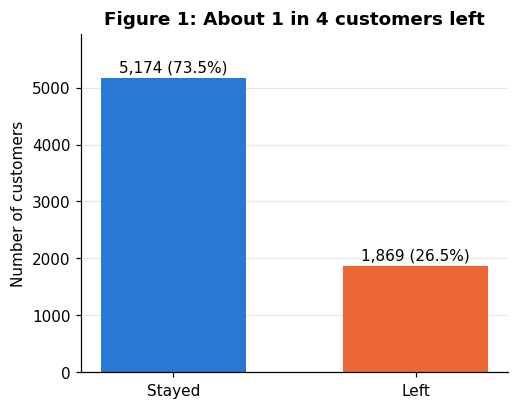

In [54]:
counts = df['Churn'].value_counts().reindex(['No', 'Yes'])
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Stayed', 'Left'], counts.values, color=[STAYED, LEFT], width=0.6)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 100, f'{n:,} ({n / len(df):.1%})', ha='center')
ax.set_title('Figure 1: About 1 in 4 customers left')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis='x', visible=False)
plt.show()

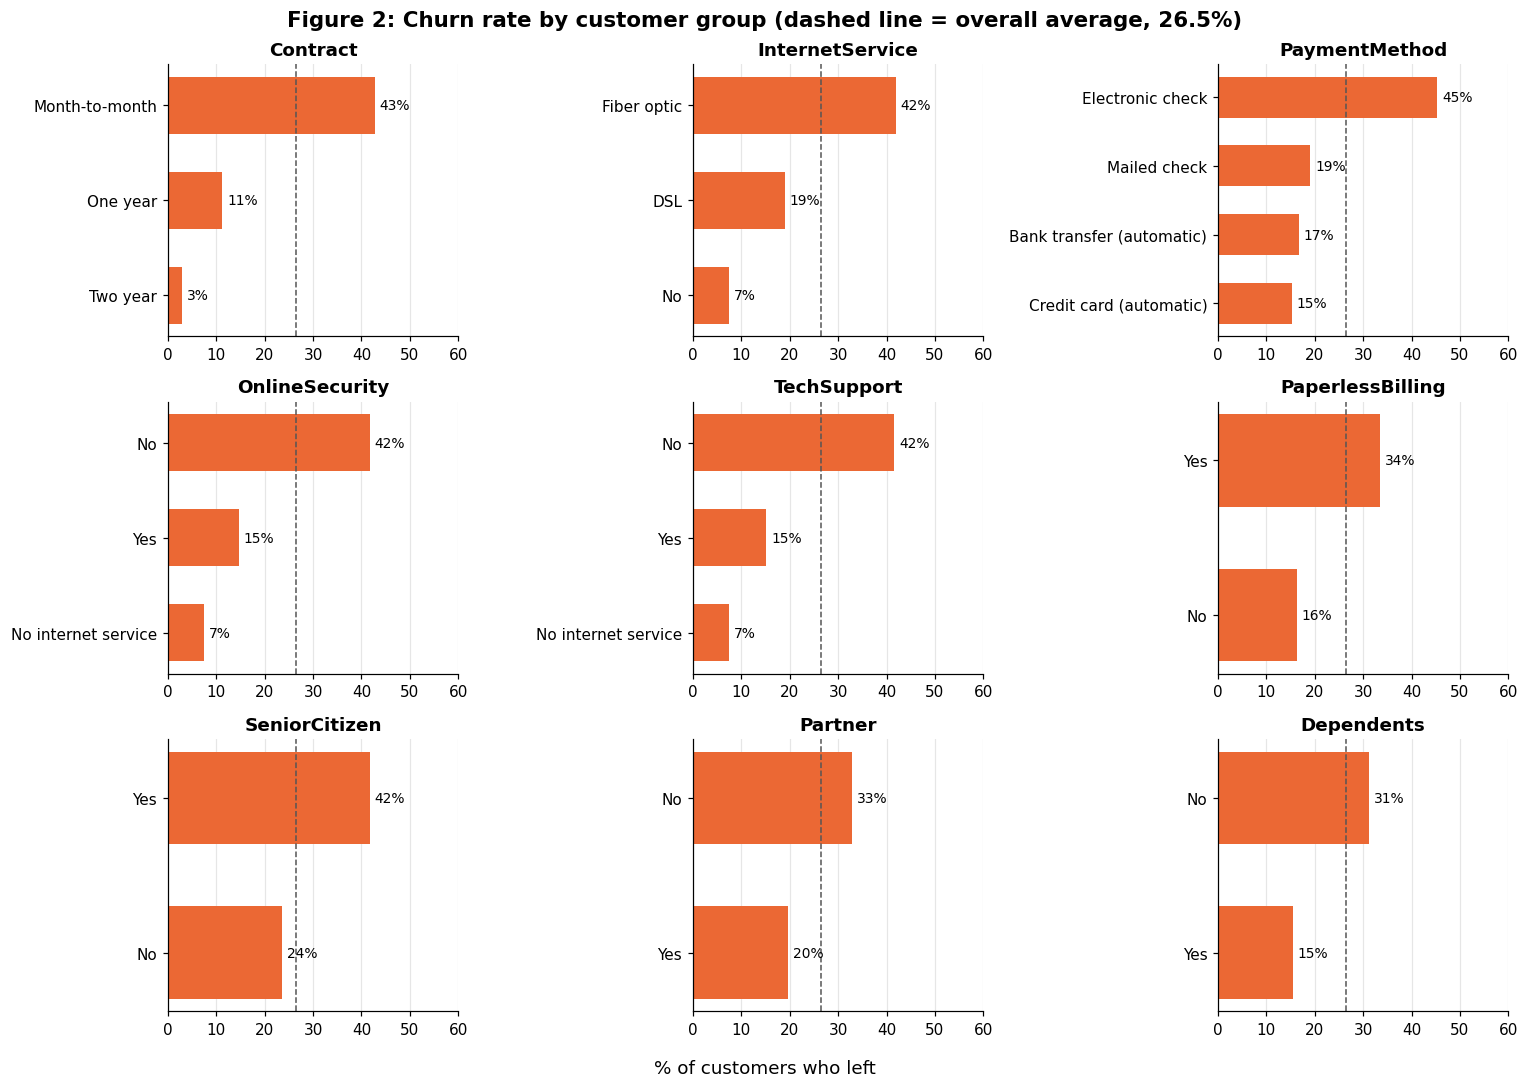

In [55]:
def churn_rate(col):
    return (is_churn.groupby(df[col]).mean() * 100).sort_values()

cols = ['Contract', 'InternetService', 'PaymentMethod',
        'OnlineSecurity', 'TechSupport', 'PaperlessBilling',
        'SeniorCitizen', 'Partner', 'Dependents']
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, cols):
    rates = churn_rate(col)
    ax.barh(rates.index, rates.values, color=LEFT, height=0.6)
    ax.axvline(overall_rate, color='#555555', linestyle='--', linewidth=1)
    for i, r in enumerate(rates.values):
        ax.text(r + 1, i, f'{r:.0f}%', va='center', fontsize=9)
    ax.set_title(col)
    ax.set_xlim(0, 60)
    ax.grid(axis='y', visible=False)
fig.suptitle(f'Figure 2: Churn rate by customer group (dashed line = overall average, {overall_rate:.1f}%)',
             fontsize=14, fontweight='bold')
fig.supxlabel('% of customers who left')
plt.tight_layout()
plt.show()

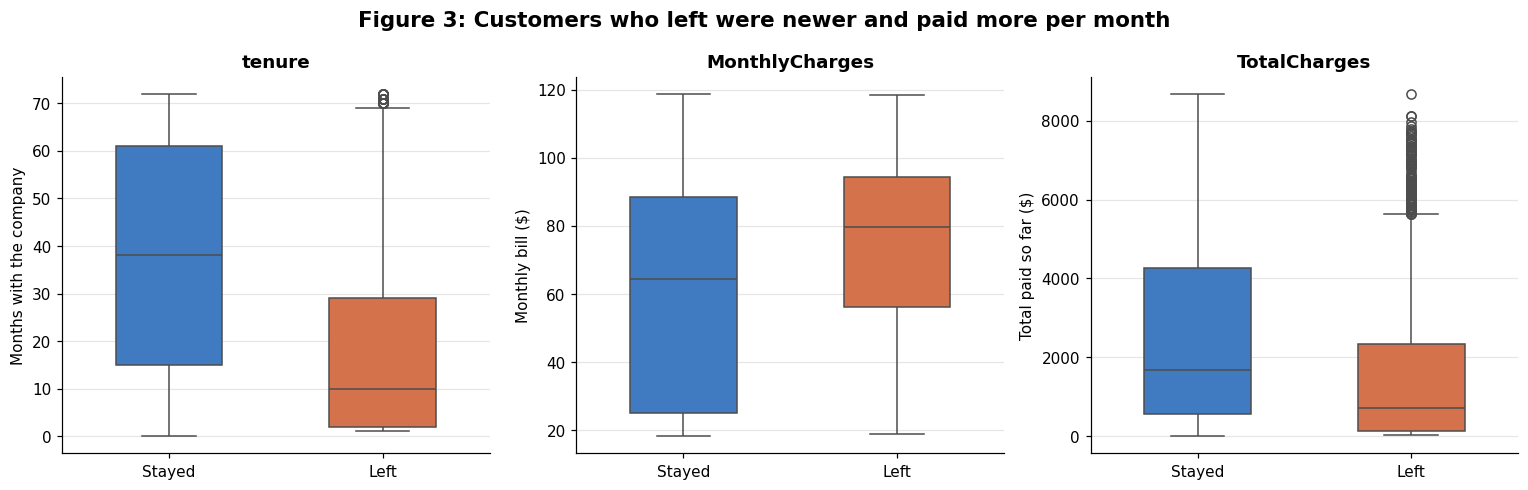

In [56]:
labels = {'tenure': 'Months with the company',
          'MonthlyCharges': 'Monthly bill ($)',
          'TotalCharges': 'Total paid so far ($)'}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (col, label) in zip(axes, labels.items()):
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn', order=['No', 'Yes'],
                palette={'No': STAYED, 'Yes': LEFT}, legend=False, width=0.5, ax=ax)
    ax.set_xticks([0, 1], ['Stayed', 'Left'])
    ax.set_xlabel('')
    ax.set_ylabel(label)
    ax.set_title(col)
    ax.grid(axis='x', visible=False)

fig.suptitle('Figure 3: Customers who left were newer and paid more per month',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

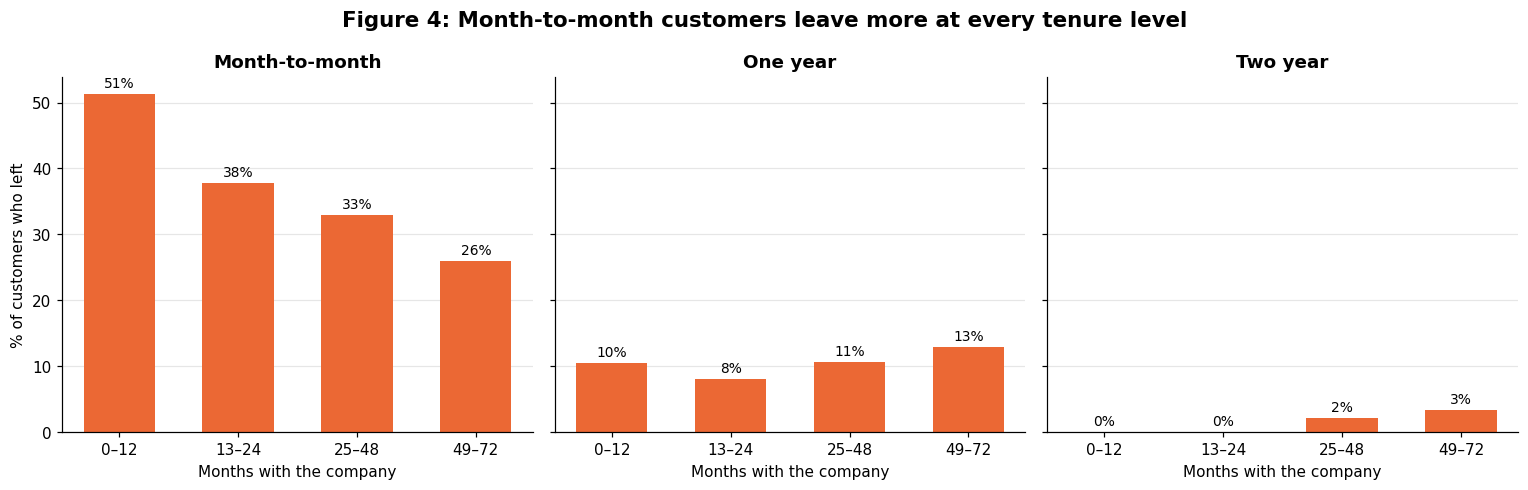

In [57]:
tenure_band = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                     labels=['0–12', '13–24', '25–48', '49–72'])
rates = is_churn.groupby([df['Contract'], tenure_band], observed=True).mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, contract in zip(axes, ['Month-to-month', 'One year', 'Two year']):
    r = rates[contract]
    ax.bar(r.index.astype(str), r.values, color=LEFT, width=0.6)
    for i, v in enumerate(r.values):
        ax.text(i, v + 1, f'{v:.0f}%', ha='center', fontsize=9)
    ax.set_title(contract)
    ax.set_xlabel('Months with the company')
    ax.grid(axis='x', visible=False)

axes[0].set_ylabel('% of customers who left')
fig.suptitle('Figure 4: Month-to-month customers leave more at every tenure level',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

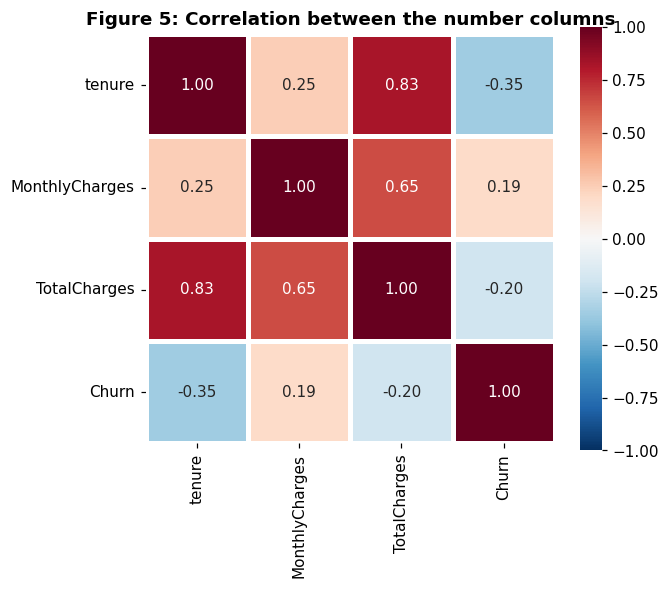

In [58]:
corr = (df[['tenure', 'MonthlyCharges', 'TotalCharges']]
        .assign(Churn=is_churn.astype(int))
        .corr())

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, ax=ax)
ax.grid(False)
ax.set_title('Figure 5: Correlation between the number columns')
plt.show()

In [59]:
data = df.drop(columns='customerID').copy()
data = data.replace({'No internet service': 'No', 'No phone service': 'No'})
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies']
data['NumAddOns'] = (data[addons] == 'Yes').sum(axis=1)
data['NewCustomer'] = (data['tenure'] <= 12).astype(int)
yes_no_cols = [c for c in data.columns if set(data[c].unique()) == {'Yes', 'No'}]
for col in yes_no_cols:
    data[col] = data[col].map({'Yes': 1, 'No': 0})
data['gender'] = (data['gender'] == 'Male').astype(int)
data = data.rename(columns={'gender': 'Male'})
data = pd.get_dummies(data, columns=['InternetService', 'Contract', 'PaymentMethod'],
                      drop_first=True, dtype=int)
print('Rows, columns:', data.shape)
data.head()

Rows, columns: (7043, 26)


,Male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,NumAddOns,NewCustomer,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,1,1,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,2,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,2,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,3,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,1,0,0,0,0,1,0


In [60]:
(data.groupby('NumAddOns')['Churn'].mean() * 100).round(1)

,Churn
NumAddOns,
0,21.4
1,45.8
2,35.8
3,27.4
4,22.3
5,12.4
6,5.3


In [61]:
from sklearn.model_selection import train_test_split

X = data.drop(columns='Churn')
y = data['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Training set:', X_train.shape, '| churn rate', round(y_train.mean() * 100, 1), '%')
print('Test set:    ', X_test.shape, '| churn rate', round(y_test.mean() * 100, 1), '%')

Training set: (5634, 25) | churn rate 26.5 %
Test set:     (1409, 25) | churn rate 26.5 %


In [62]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
baseline = DummyClassifier(strategy='most_frequent')
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
rand_forest = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)
baseline.fit(X_train, y_train)
log_reg.fit(X_train, y_train)
rand_forest.fit(X_train, y_train)
print('All three models trained.')

All three models trained.


In [63]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
def evaluate(model, name):
    pred = model.predict(X_test)
    return {'Model': name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred)}

results = pd.DataFrame([
    evaluate(baseline, 'Baseline (always "stayed")'),
    evaluate(log_reg, 'Logistic Regression'),
    evaluate(rand_forest, 'Random Forest'),
]).set_index('Model').round(3)
results

,Accuracy,Precision,Recall,F1
Model,,,,
"Baseline (always ""stayed"")",0.735,0.000,0.000,0.000
Logistic Regression,0.735,0.500,0.794,0.614
Random Forest,0.784,0.619,0.479,0.540


In [64]:
from sklearn.model_selection import GridSearchCV
lr_search = GridSearchCV(log_reg, {'logisticregression__C': [0.01, 0.1, 1, 10]},
                         scoring='f1', cv=5)
rf_search = GridSearchCV(rand_forest, {'max_depth': [5, 8, 12, None],
                                       'min_samples_leaf': [1, 5, 10]},
                         scoring='f1', cv=5)
lr_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)
best_lr = lr_search.best_estimator_
best_rf = rf_search.best_estimator_
print('Best Logistic Regression settings:', lr_search.best_params_,
      '| F1 in cross-validation:', round(lr_search.best_score_, 3))
print('Best Random Forest settings:      ', rf_search.best_params_,
      '| F1 in cross-validation:', round(rf_search.best_score_, 3))

Best Logistic Regression settings: {'logisticregression__C': 0.01} | F1 in cross-validation: 0.632
Best Random Forest settings:       {'max_depth': 8, 'min_samples_leaf': 10} | F1 in cross-validation: 0.637


In [65]:
results = pd.DataFrame([
    evaluate(baseline, 'Baseline (always "stayed")'),
    evaluate(log_reg, 'Logistic Regression'),
    evaluate(rand_forest, 'Random Forest'),
    evaluate(best_lr, 'Logistic Regression (tuned)'),
    evaluate(best_rf, 'Random Forest (tuned)'),
]).set_index('Model').round(3)
results

,Accuracy,Precision,Recall,F1
Model,,,,
"Baseline (always ""stayed"")",0.735,0.000,0.000,0.000
Logistic Regression,0.735,0.500,0.794,0.614
Random Forest,0.784,0.619,0.479,0.540
Logistic Regression (tuned),0.740,0.506,0.778,0.613
Random Forest (tuned),0.757,0.528,0.783,0.631


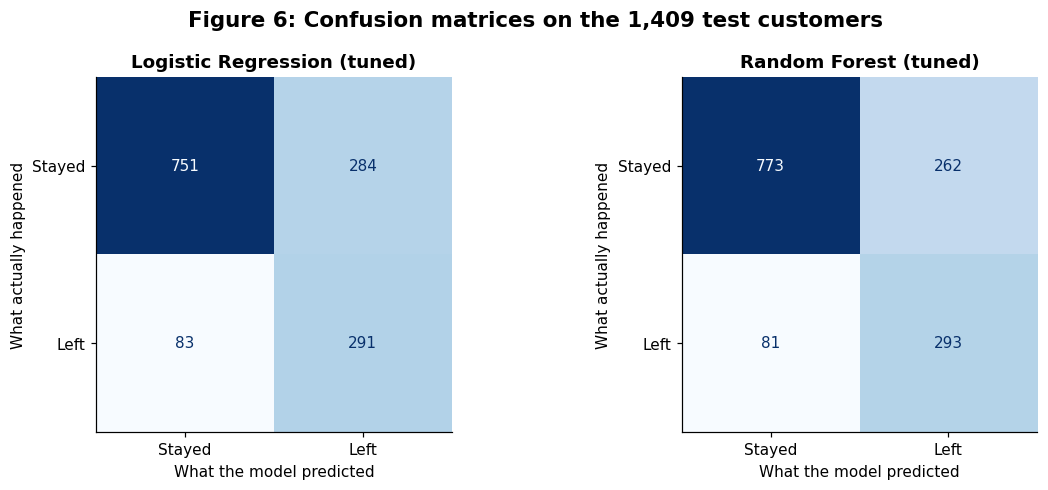

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (model, name) in zip(axes, [(best_lr, 'Logistic Regression (tuned)'),
                                    (best_rf, 'Random Forest (tuned)')]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test,
                                          display_labels=['Stayed', 'Left'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
    ax.set_xlabel('What the model predicted')
    ax.set_ylabel('What actually happened')

fig.suptitle('Figure 6: Confusion matrices on the 1,409 test customers',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [67]:
import joblib
if lr_search.best_score_ >= rf_search.best_score_:
    best_model, best_name = best_lr, 'Logistic Regression (tuned)'
else:
    best_model, best_name = best_rf, 'Random Forest (tuned)'

joblib.dump(best_model, 'churn_model.joblib')
print('Best model:', best_name, '- saved as churn_model.joblib')

Best model: Random Forest (tuned) - saved as churn_model.joblib


In [68]:
model = joblib.load('churn_model.joblib')
sample = X_test.head(8)

demo = pd.DataFrame({
    'tenure': sample['tenure'],
    'MonthlyCharges': sample['MonthlyCharges'],
    'Chance of leaving': (model.predict_proba(sample)[:, 1] * 100).round().astype(int).astype(str) + '%',
    'Model says': ['Leave' if p == 1 else 'Stay' for p in model.predict(sample)],
    'Actually': ['Left' if v == 1 else 'Stayed' for v in y_test.head(8)],
})
demo

,tenure,MonthlyCharges,Chance of leaving,Model says,Actually
437,72,114.05,5%,Stay,Stayed
2280,8,100.15,88%,Leave,Stayed
2235,41,78.35,21%,Stay,Stayed
4460,18,78.20,59%,Leave,Stayed
3761,72,82.65,5%,Stay,Stayed
5748,21,99.85,71%,Leave,Stayed
3568,21,99.15,63%,Leave,Stayed
2976,19,24.10,18%,Stay,Stayed


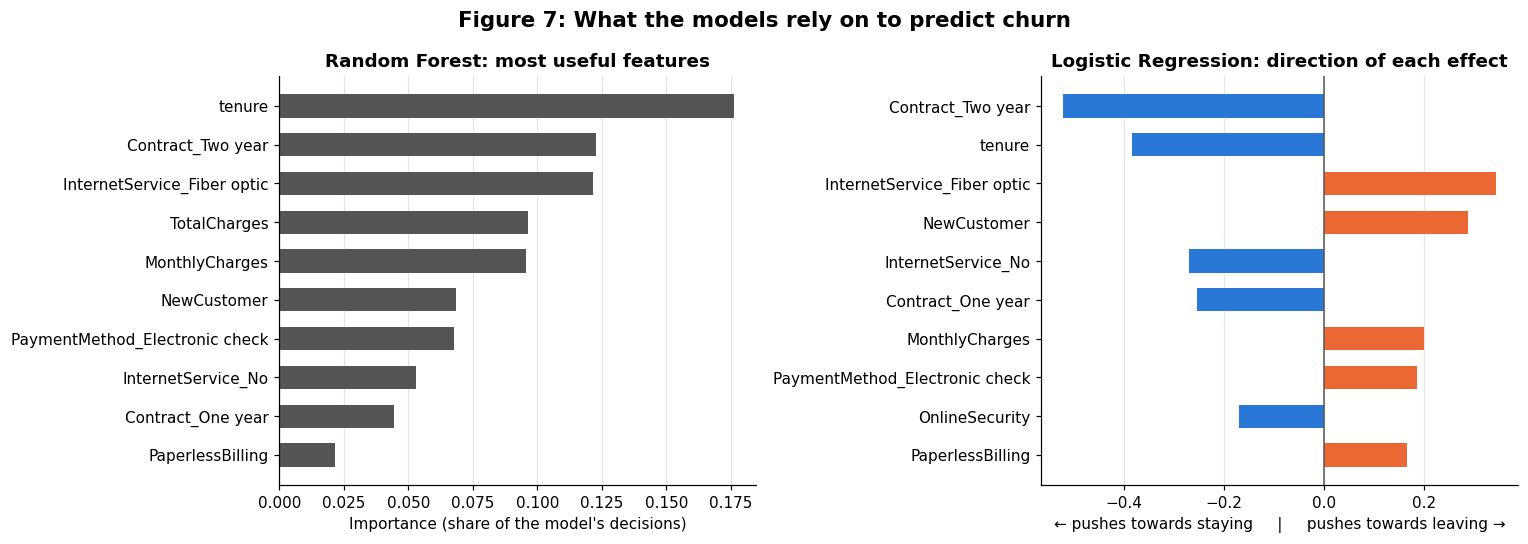

In [69]:
rf_importance = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values().tail(10)
lr_coefs = pd.Series(best_lr.named_steps['logisticregression'].coef_[0], index=X.columns)
lr_top = lr_coefs[lr_coefs.abs().sort_values().tail(10).index]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(rf_importance.index, rf_importance.values, color='#555555', height=0.6)
axes[0].set_title('Random Forest: most useful features')
axes[0].set_xlabel("Importance (share of the model's decisions)")
axes[0].grid(axis='y', visible=False)
axes[1].barh(lr_top.index, lr_top.values,
           color=[LEFT if v > 0 else STAYED for v in lr_top.values], height=0.6)
axes[1].axvline(0, color='#555555', linewidth=1)
axes[1].set_title('Logistic Regression: direction of each effect')
axes[1].set_xlabel('← pushes towards staying     |     pushes towards leaving →')
axes[1].grid(axis='y', visible=False)
fig.suptitle('Figure 7: What the models rely on to predict churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [70]:
test_pred = best_model.predict(X_test)
def group_report(col, groups):
    rows = []
    for value, label in groups.items():
        in_group = X_test[col] == value
        rows.append({
            'Group': label,
            'Customers': in_group.sum(),
            'Actually left': y_test[in_group].mean(),
            'Flagged by model': test_pred[in_group].mean(),
            'Precision': precision_score(y_test[in_group], test_pred[in_group]),
            'Recall': recall_score(y_test[in_group], test_pred[in_group]),
        })
    return rows
fairness = pd.DataFrame(
    group_report('SeniorCitizen', {0: 'Not senior', 1: 'Senior'}) +
    group_report('Male', {0: 'Female', 1: 'Male'})
).set_index('Group')

fairness.style.format({'Actually left': '{:.0%}', 'Flagged by model': '{:.0%}',
                       'Precision': '{:.0%}', 'Recall': '{:.0%}'})

,Customers,Actually left,Flagged by model,Precision,Recall
Group,,,,,
Not senior,1187,23%,35%,50%,75%
Senior,222,44%,63%,61%,87%
Female,687,28%,39%,54%,76%
Male,722,25%,40%,51%,81%


In [71]:
from sklearn.base import clone
sensitive = ['SeniorCitizen', 'Male']
fair_model = clone(best_model).fit(X_train.drop(columns=sensitive), y_train)
fair_pred = fair_model.predict(X_test.drop(columns=sensitive))
is_senior = X_test['SeniorCitizen'] == 1
pd.DataFrame({
    'With age & gender': [f1_score(y_test, test_pred),
                          test_pred[is_senior].mean(), test_pred[~is_senior].mean()],
    'Without age & gender': [f1_score(y_test, fair_pred),
                             fair_pred[is_senior].mean(), fair_pred[~is_senior].mean()],
}, index=['F1 score', '% of seniors flagged', '% of non-seniors flagged']).round(3)

,With age & gender,Without age & gender
F1 score,0.631,0.629
% of seniors flagged,0.626,0.622
% of non-seniors flagged,0.350,0.351


In [72]:
import numpy as np
risk = pd.DataFrame({
    'chance_of_leaving': best_model.predict_proba(X_test)[:, 1],
    'actually_left': y_test.values,
    'monthly_bill': X_test['MonthlyCharges'].values,
}).sort_values('chance_of_leaving', ascending=False).reset_index(drop=True)
total_leavers = risk['actually_left'].sum()
rows = []
for share in [0.10, 0.20, 0.30, 0.40, 0.50]:
    top = risk.head(int(len(risk) * share))
    rows.append({
        'Contact the riskiest': f'{share:.0%}',
        'Customers contacted': len(top),
        'Leavers reached': top['actually_left'].sum(),
        '% of all leavers reached': top['actually_left'].sum() / total_leavers,
        'Hit rate (leavers / contacted)': top['actually_left'].mean(),
        'Monthly revenue of leavers reached ($)': top.loc[top['actually_left'] == 1, 'monthly_bill'].sum(),
    })

gains = pd.DataFrame(rows).set_index('Contact the riskiest')
gains.style.format({'% of all leavers reached': '{:.0%}', 'Hit rate (leavers / contacted)': '{:.0%}',
                    'Monthly revenue of leavers reached ($)': '${:,.0f}'})

,Customers contacted,Leavers reached,% of all leavers reached,Hit rate (leavers / contacted),Monthly revenue of leavers reached ($)
Contact the riskiest,,,,,
10%,140,104,28%,74%,"$8,438"
20%,281,186,50%,66%,"$14,290"
30%,422,249,67%,59%,"$19,030"
40%,563,294,79%,52%,"$21,787"
50%,704,327,87%,46%,"$24,435"


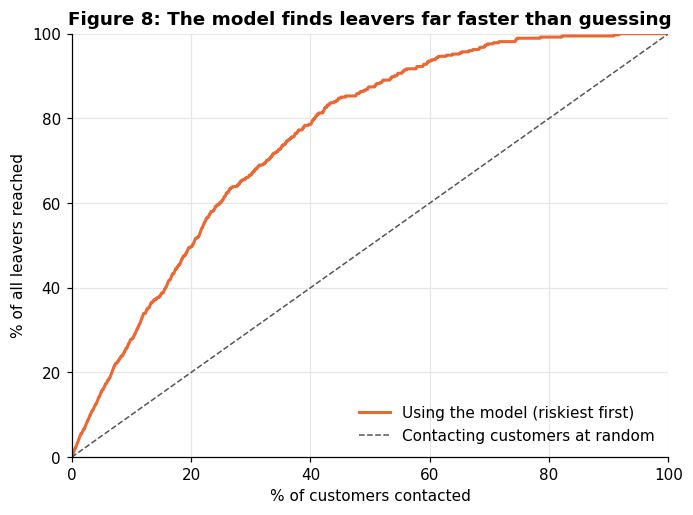

In [73]:
caught = risk['actually_left'].cumsum() / total_leavers * 100
contacted = np.arange(1, len(risk) + 1) / len(risk) * 100

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(contacted, caught, color=LEFT, linewidth=2, label='Using the model (riskiest first)')
ax.plot([0, 100], [0, 100], color='#555555', linestyle='--', linewidth=1,
        label='Contacting customers at random')
ax.set_xlabel('% of customers contacted')
ax.set_ylabel('% of all leavers reached')
ax.set_title('Figure 8: The model finds leavers far faster than guessing')
ax.legend(loc='lower right', frameon=False)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
plt.show()